# 02 - Calidad MIBGAS -> processed

Este notebook lee los CSV anuales, filtra el producto diario D+1 por fecha de entrega, normaliza los precios, deduplica y genera un informe de cobertura.

In [1]:
import sys
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.project import find_project_root

PROJECT_ROOT = find_project_root(PROJECT_ROOT)
from src.config.mibgas import load_mibgas_config
from src.calidad.mibgas import deduplicate_records, normalize_records, read_raw_file
from src.calidad.pipeline import collect_file_results, save_quality_report, save_values_json

MIBGAS_CONFIG_PATH = PROJECT_ROOT / 'config' / 'mibgas.yml'
MODEL_CONFIG_PATH = PROJECT_ROOT / 'config' / 'modelo.yml'
CONFIG = load_mibgas_config(MIBGAS_CONFIG_PATH, MODEL_CONFIG_PATH)
MIBGAS = CONFIG['mibgas']
MODEL = MIBGAS['model']
PRODUCT = MIBGAS['product']
RAW_DIR = PROJECT_ROOT / 'data' / 'raw' / 'mibgas'
OUT_DIR = PROJECT_ROOT / 'data' / 'processed' / 'mibgas'
START = pd.Timestamp(MODEL['history_start']).date()
END = pd.Timestamp(MODEL['history_end']).date()

ModuleNotFoundError: No module named 'src'

In [ ]:
raw_files = sorted(RAW_DIR.glob('MIBGAS_Data_*.csv'))
if not raw_files:
    raise FileNotFoundError(f'No hay CSV raw MIBGAS en {RAW_DIR}')

def process_file(path: Path) -> tuple[pd.DataFrame, dict[str, int]]:
    raw_values = read_raw_file(path)
    normalized, report = normalize_records(
        raw_values,
        START,
        END,
        product_code=PRODUCT['code'],
        place_of_delivery=PRODUCT['place_of_delivery'],
        area=PRODUCT['area'],
    )
    return normalized, report | {'source_file': path.name}

values, reports = collect_file_results(raw_files, process_file)
values, duplicates_removed = deduplicate_records(values)
quality_report = {
    'configured_window': {'start': str(START), 'end': str(END)},
    'raw_files': len(raw_files),
    'reports': reports,
    'output_records': len(values),
    'duplicates_removed': duplicates_removed,
}
save_values_json(values, OUT_DIR / 'mibgas_d1.json')
save_quality_report(quality_report, OUT_DIR / 'calidad_mibgas.json')
quality_report

{'configured_window': {'start': '2024-10-01', 'end': '2026-09-30'},
 'raw_files': 3,
 'reports': [{'input_records': 1129,
   'output_records': 93,
   'invalid_dates': 0,
   'invalid_prices': 0,
   'outside_window': 568,
   'filtered_by_product': 468,
   'source_file': 'MIBGAS_Data_2024.csv'},
  {'input_records': 1127,
   'output_records': 366,
   'invalid_dates': 0,
   'invalid_prices': 0,
   'outside_window': 0,
   'filtered_by_product': 761,
   'source_file': 'MIBGAS_Data_2025.csv'},
  {'input_records': 1129,
   'output_records': 317,
   'invalid_dates': 0,
   'invalid_prices': 0,
   'outside_window': 429,
   'filtered_by_product': 383,
   'source_file': 'MIBGAS_Data_2026.csv'}],
 'output_records': 730,
 'duplicates_removed': 46}

## 1. Diagnóstico visual

Se comprueba la cobertura y la evolución del precio D+1 por fecha de entrega.

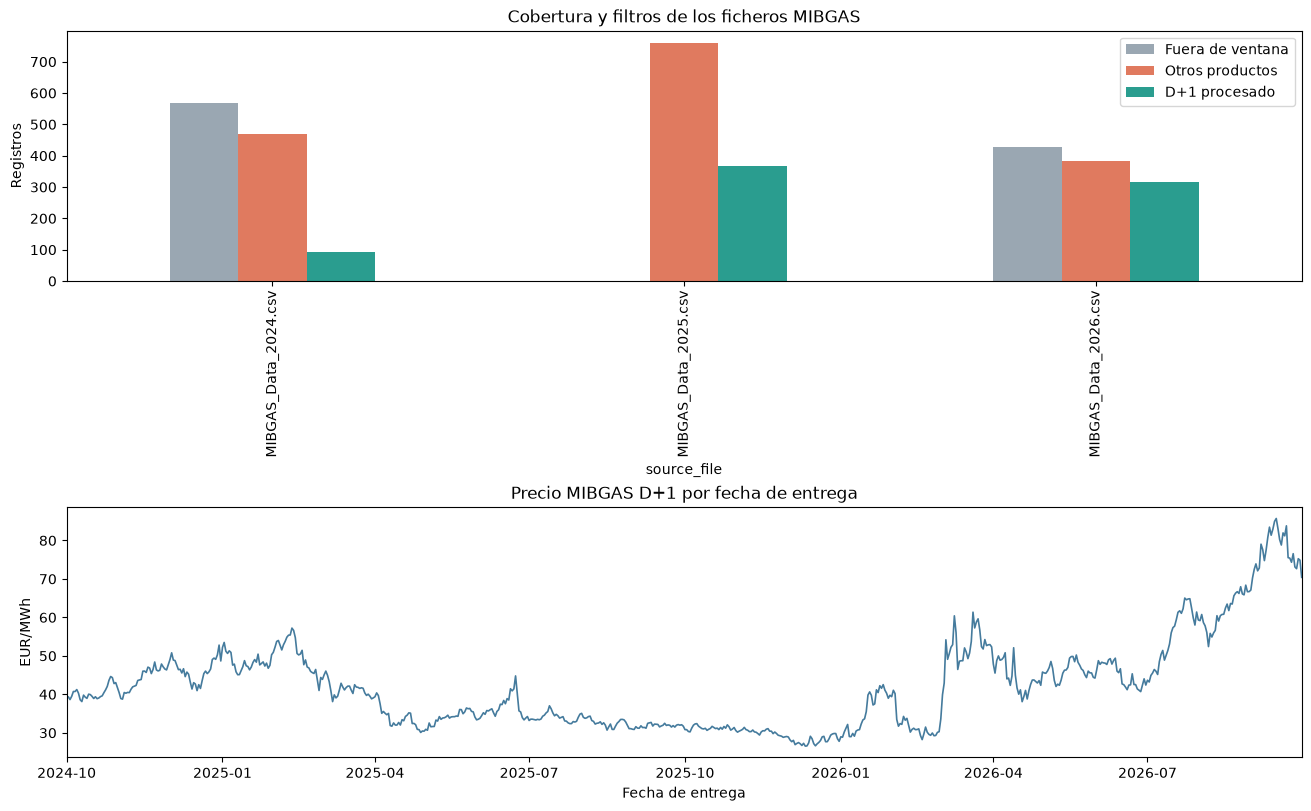

,source_file,within_window,filtered_by_product,output_records
0,MIBGAS_Data_2024.csv,561,468,93
1,MIBGAS_Data_2025.csv,1127,761,366
2,MIBGAS_Data_2026.csv,700,383,317


In [ ]:
import matplotlib.pyplot as plt

coverage = pd.DataFrame(reports)
coverage['within_window'] = coverage['input_records'] - coverage['outside_window']
fig, axes = plt.subplots(2, 1, figsize=(13, 8), constrained_layout=True)
coverage.set_index('source_file')[['outside_window', 'filtered_by_product', 'output_records']].plot.bar(ax=axes[0], color=['#9aa7b2', '#e07a5f', '#2a9d8f'])
axes[0].set_title('Cobertura y filtros de los ficheros MIBGAS')
axes[0].set_ylabel('Registros')
axes[0].legend(['Fuera de ventana', 'Otros productos', 'D+1 procesado'])

plot_values = values.copy()
plot_values['fecha_entrega'] = pd.to_datetime(plot_values['fecha_entrega'])
plot_values = plot_values.sort_values('fecha_entrega')
axes[1].plot(plot_values['fecha_entrega'], plot_values['precio_eur_mwh'], color='#457b9d', linewidth=1.2)
axes[1].set_title('Precio MIBGAS D+1 por fecha de entrega')
axes[1].set_ylabel('EUR/MWh')
axes[1].set_xlabel('Fecha de entrega')
axes[1].set_xlim(pd.Timestamp(START), pd.Timestamp(END))
plt.show()
coverage[['source_file', 'within_window', 'filtered_by_product', 'output_records']]